In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns
import plotly.express as px 

from sklearn.preprocessing import LabelEncoder , OrdinalEncoder ,StandardScaler
from category_encoders import BinaryEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.compose import TransformedTargetRegressor
from sklearn import set_config
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split ,GridSearchCV
from sklearn.metrics import mean_absolute_error , mean_squared_error , r2_score 
from sklearn.model_selection import learning_curve
import joblib

import warnings

warnings.filterwarnings("ignore")

print("modules are imported ")

modules are imported 


In [2]:
odf=pd.read_csv('hatla2ee_scraped_data.csv')
odf.head()

,Name,Price,Color,Mileage,Make,Model,City,Date Displayed,Automatic Transmission,Air Conditioner,Power Steering,Remote Control,Item URL
0,Kia Sportage 2024,"2,800,000 EGP",Dark grey,300 Km,Kia,Sportage,Tagamo3 - New Cairo,2024-02-16,Yes,Yes,Yes,Yes,https://eg.hatla2ee.com/en/car/kia/sportage/62...
1,Chery Arrizo 5 2022,NaN,Bronze,"86,000 Km",Chery,Arrizo 5,Nasr city,2024-02-16,Yes,Yes,Yes,Yes,https://eg.hatla2ee.com/en/car/chery/Arrizo-5/...
2,Fiat Tipo 2021,"1,200,000 EGP",Petroleum,"131,000 Km",Fiat,Tipo,Kafr el-Dawwar,2024-02-16,Yes,Yes,Yes,Yes,https://eg.hatla2ee.com/en/car/fiat/tipo/6286701
3,Hyundai Tucson Turbo GDI 2021,"2,050,000 EGP",Black,"125,000 Km",Hyundai,Tucson Turbo GDI,Nasr city,2024-02-16,Yes,Yes,Yes,Yes,https://eg.hatla2ee.com/en/car/hyundai/Tucson-...
4,BMW X1 2018,"2,050,000 EGP",Gray,"84,000 Km",BMW,X1,Cairo,2024-02-16,Yes,Yes,Yes,Yes,https://eg.hatla2ee.com/en/car/bmw/x1/6254123


In [3]:
# examin the duplicated rows by thier URL 
print(odf['Item URL'].duplicated().sum())
odf.drop_duplicates(subset='Item URL', inplace=True)
print(odf['Item URL'].duplicated().sum())


11511
0


In [4]:
print("Missing prices before:", odf["Price"].isnull().sum())
odf.dropna(subset=["Price"], inplace=True)
print("Missing prices after:", odf["Price"].isnull().sum())

Missing prices before: 71
Missing prices after: 0


In [5]:
odf["Price"] = pd.to_numeric(odf["Price"].str.replace(",", "", regex=False).str.extract(r"(\d+)")[0], errors="coerce")
odf["Mileage"] = pd.to_numeric(odf["Mileage"].str.replace(",", "", regex=False).str.extract(r"(\d+)")[0], errors="coerce")
odf["Year"] = pd.to_numeric(odf["Name"].str.extract(r"((?:19|20)\d{2})")[0], errors="coerce")

In [6]:

print(odf.describe().T)
print("_______________________")
print(odf.info())

           count           mean            std     min       25%       50%  \
Price    21977.0  847586.997452  931985.348223  1060.0  360000.0  615000.0   
Mileage  20783.0  135024.501756   87767.431824     0.0   70000.0  127000.0   
Year     21976.0    2013.332272       8.797056  1963.0    2009.0    2015.0   

              75%         max  
Price    950000.0  20000000.0  
Mileage  190000.0   2226000.0  
Year       2020.0      2024.0  
_______________________
<class 'pandas.DataFrame'>
Index: 21977 entries, 0 to 31735
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Name                    21977 non-null  str    
 1   Price                   21977 non-null  int64  
 2   Color                   21977 non-null  str    
 3   Mileage                 20783 non-null  float64
 4   Make                    21977 non-null  str    
 5   Model                   21977 non-null  str    
 6   City         

In [7]:

odf["car_age"]=2024-odf["Year"]
odf["milePyear"]=odf["Mileage"]/(odf["car_age"]+1)

option_cols = ['Automatic Transmission', 'Air Conditioner', 'Power Steering', 'Remote Control']
odf['Options_Score'] = (odf[option_cols] == 'Yes').sum(axis=1)

train_df, test_df = train_test_split(odf, test_size=0.2, random_state=42)
# defining lexurniess score (traninf df )
global_median = train_df["Price"].median()
brand_medians = train_df.groupby("Make")["Price"].median()

train_df["Luxury_Score"] = (train_df["Make"].map(brand_medians) / global_median).round(2)
test_df["Luxury_Score"] = (
    test_df["Make"].map(brand_medians) / global_median).fillna(1.0).round(2)

In [8]:
train_df=train_df.drop(['Name','Item URL','Date Displayed','City','Year'],axis=1)
print(train_df.info())

<class 'pandas.DataFrame'>
Index: 17581 entries, 5786 to 15848
Data columns (total 13 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Price                   17581 non-null  int64  
 1   Color                   17581 non-null  str    
 2   Mileage                 16643 non-null  float64
 3   Make                    17581 non-null  str    
 4   Model                   17581 non-null  str    
 5   Automatic Transmission  17581 non-null  str    
 6   Air Conditioner         17581 non-null  str    
 7   Power Steering          17581 non-null  str    
 8   Remote Control          17581 non-null  str    
 9   car_age                 17581 non-null  float64
 10  milePyear               16643 non-null  float64
 11  Options_Score           17581 non-null  int64  
 12  Luxury_Score            17581 non-null  float64
dtypes: float64(4), int64(2), str(7)
memory usage: 2.4 MB
None


In [9]:
test_df=test_df.drop(['Name','Item URL','Date Displayed','City','Year'],axis=1)
print(test_df.info())

<class 'pandas.DataFrame'>
Index: 4396 entries, 16725 to 7205
Data columns (total 13 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Price                   4396 non-null   int64  
 1   Color                   4396 non-null   str    
 2   Mileage                 4140 non-null   float64
 3   Make                    4396 non-null   str    
 4   Model                   4396 non-null   str    
 5   Automatic Transmission  4396 non-null   str    
 6   Air Conditioner         4396 non-null   str    
 7   Power Steering          4396 non-null   str    
 8   Remote Control          4396 non-null   str    
 9   car_age                 4395 non-null   float64
 10  milePyear               4140 non-null   float64
 11  Options_Score           4396 non-null   int64  
 12  Luxury_Score            4396 non-null   float64
dtypes: float64(4), int64(2), str(7)
memory usage: 603.9 KB
None


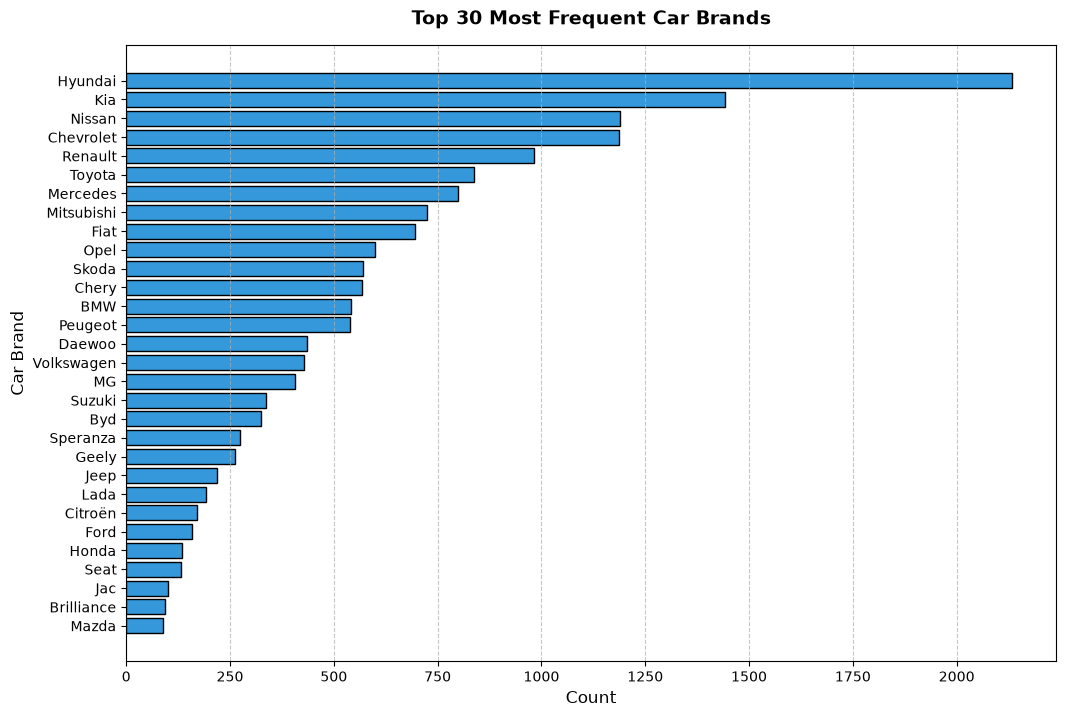

In [10]:
top_30_brands = train_df['Make'].value_counts().head(30)
plt.figure(figsize=(12, 8))
plt.barh(top_30_brands.index[::-1], top_30_brands.values[::-1], color='#3498db', edgecolor='black')
plt.title('Top 30 Most Frequent Car Brands', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Count', fontsize=12)
plt.ylabel('Car Brand', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.show()


<Axes: ylabel='Price'>

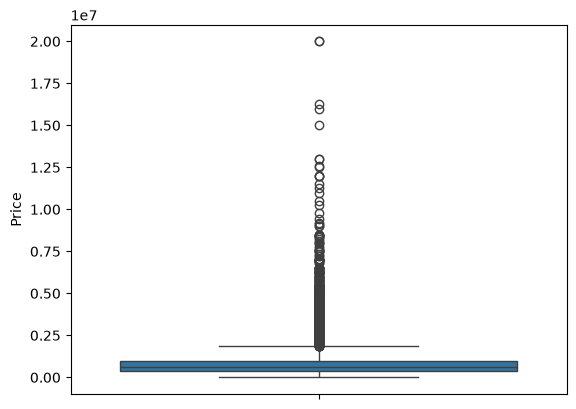

In [11]:
sns.boxplot(train_df["Price"])

<Axes: xlabel='Price', ylabel='Count'>

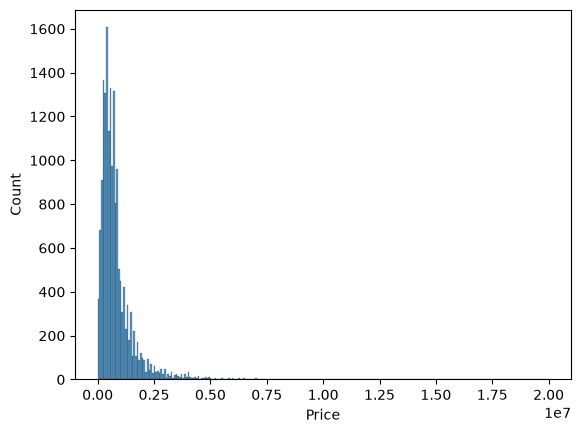

In [12]:
sns.histplot(train_df["Price"])

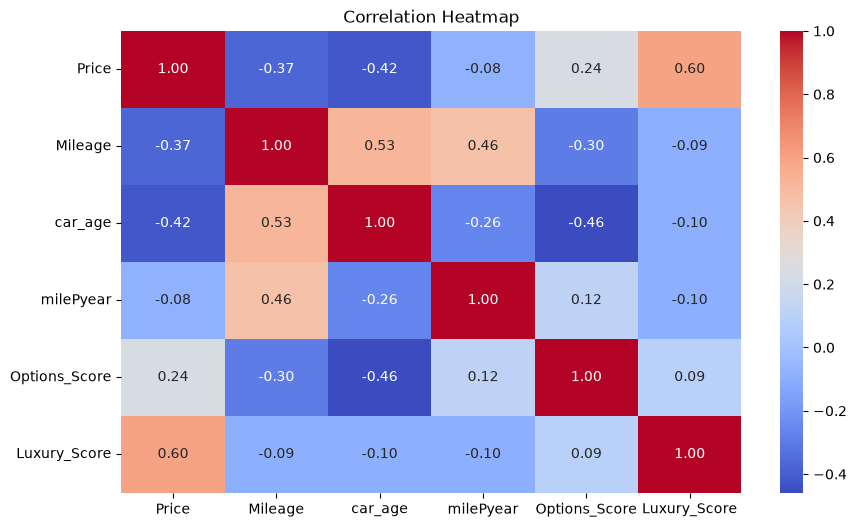

In [13]:
numeric_cols = train_df.select_dtypes(include=['number'])
plt.figure(figsize=(10, 6))
sns.heatmap(numeric_cols.corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Heatmap')
plt.show()

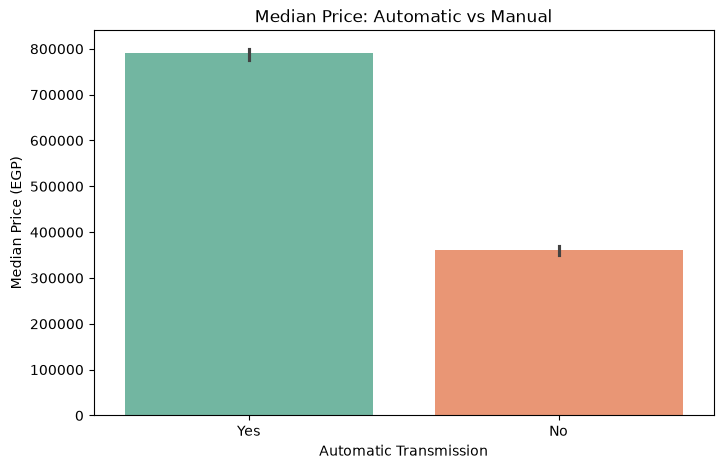

In [14]:
plt.figure(figsize=(8, 5))
sns.barplot(data=train_df, x='Automatic Transmission', y='Price', estimator='median', palette='Set2')
plt.title('Median Price: Automatic vs Manual')
plt.ylabel('Median Price (EGP)')
plt.show()

In [15]:
binary=[]
ordinal=[]
for i in train_df.select_dtypes(include='object').columns:
    print(f"{i}  : {train_df[i].nunique()}")
    if train_df[i].nunique()==2 :
        ordinal.append(i)
    else :
        binary.append(i)

numeric_cols=train_df.select_dtypes(include='number').columns.tolist()
numeric_cols.remove("Price")

Color  : 24
Make  : 97
Model  : 830
Automatic Transmission  : 2
Air Conditioner  : 2
Power Steering  : 2
Remote Control  : 2


In [16]:
X_train = train_df.drop(columns=["Price"])
y_train = train_df["Price"]
X_test = test_df.drop(columns=["Price"])
y_test =test_df["Price"]

In [17]:
print(y_train.isna().sum())
print(y_test.isna().sum())

0
0


In [20]:


numeric=Pipeline([
    ("imputer",SimpleImputer(strategy="median"))
    ,("scalin",StandardScaler())
    ])
binary_pipe = Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),("encoder", BinaryEncoder()),])
ordinal_pipe = Pipeline([("imputer", SimpleImputer(strategy="most_frequent"))
,("encoder", OrdinalEncoder(handle_unknown="use_encoded_value",unknown_value=-1)),])

preprocessor = ColumnTransformer(
    transformers=[("num", numeric, numeric_cols),
        ("bin", binary_pipe, binary),
        ("ord", ordinal_pipe, ordinal),],
    remainder="drop",)

base_pipeline = Pipeline([
    ("preprocess", preprocessor),
    ("regressor", None),])

In [ ]:
import sklearn
sklearn.set_config(transform_output="default")
pipe.set_output(transform="default")

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('regressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('bin', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.

In [23]:
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from catboost import CatBoostRegressor
models = {
    "Ridge": Ridge(random_state=42),
    "Random Forest": RandomForestRegressor(random_state=42, n_jobs=-1),
    "XGBoost": XGBRegressor(
        random_state=42, n_jobs=-1, objective="reg:squarederror"
    ),
    "CatBoost": CatBoostRegressor(verbose=0, random_state=42),
}

# NOTE the double prefix: regressor__regressor__...
# Pipeline step name  →  "regressor"  (TransformedTargetRegressor)
# Inner model param   →  "regressor"  (the actual Ridge / RF / ...)
param_grids = {
    "Ridge": {
        "regressor__regressor__alpha": [0.1, 1.0, 10.0, 100.0],
    },
    "Random Forest": {
        "regressor__regressor__n_estimators": [100, 200],
        "regressor__regressor__max_depth": [10, 20, None],
        "regressor__regressor__min_samples_split": [2, 5],
    },
    "XGBoost": {
        "regressor__regressor__n_estimators": [200, 400],
        "regressor__regressor__learning_rate": [0.05, 0.1],
        "regressor__regressor__max_depth": [4, 6],
        "regressor__regressor__subsample": [0.8, 1.0],
    },
    "CatBoost": {
        "regressor__regressor__iterations": [300, 500],
        "regressor__regressor__learning_rate": [0.03, 0.1],
        "regressor__regressor__depth": [4, 6],
    },
}

results = {}

for name, model in models.items():
    # wrap model so it trains on log(price) and predicts in EGP
    tt_regressor = TransformedTargetRegressor(
        regressor=model,
        func=np.log1p,
        inverse_func=np.expm1,
    )

    pipe = Pipeline([
        ("preprocess", preprocessor),
        ("regressor", tt_regressor),   # step name = "regressor"
    ])

    search = GridSearchCV(
        estimator=pipe,
        param_grid=param_grids[name],
        cv=3,
        scoring="neg_mean_absolute_error",
        n_jobs=-1,
        verbose=1,
        error_score="raise",
    )

    # y_train / y_test stay in ORIGINAL EGP (no manual log)
    search.fit(X_train, y_train)

    y_pred = search.predict(X_test)  # already back on EGP scale

    results[name] = {
        "best_params": search.best_params_,
        "MAE":  mean_absolute_error(y_test, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
        "R2":   r2_score(y_test, y_pred),
        "model": search.best_estimator_,
    }

    print(f"\n{name}")
    print(f"  Best: {search.best_params_}")
    print(f"  MAE:  {results[name]['MAE']:,.0f} EGP")
    print(f"  RMSE: {results[name]['RMSE']:,.0f} EGP")
    print(f"  R2:   {results[name]['R2']:.3f}")

Fitting 3 folds for each of 4 candidates, totalling 12 fits

Ridge
  Best: {'regressor__regressor__alpha': 100.0}
  MAE:  270,515 EGP
  RMSE: 785,516 EGP
  R2:   0.245
Fitting 3 folds for each of 12 candidates, totalling 36 fits

Random Forest
  Best: {'regressor__regressor__max_depth': None, 'regressor__regressor__min_samples_split': 5, 'regressor__regressor__n_estimators': 200}
  MAE:  157,510 EGP
  RMSE: 409,779 EGP
  R2:   0.795
Fitting 3 folds for each of 16 candidates, totalling 48 fits

XGBoost
  Best: {'regressor__regressor__learning_rate': 0.1, 'regressor__regressor__max_depth': 6, 'regressor__regressor__n_estimators': 400, 'regressor__regressor__subsample': 0.8}
  MAE:  152,934 EGP
  RMSE: 361,629 EGP
  R2:   0.840
Fitting 3 folds for each of 8 candidates, totalling 24 fits

CatBoost
  Best: {'regressor__regressor__depth': 6, 'regressor__regressor__iterations': 500, 'regressor__regressor__learning_rate': 0.1}
  MAE:  157,189 EGP
  RMSE: 380,307 EGP
  R2:   0.823


In [24]:
best_model=results['XGBoost']['model']

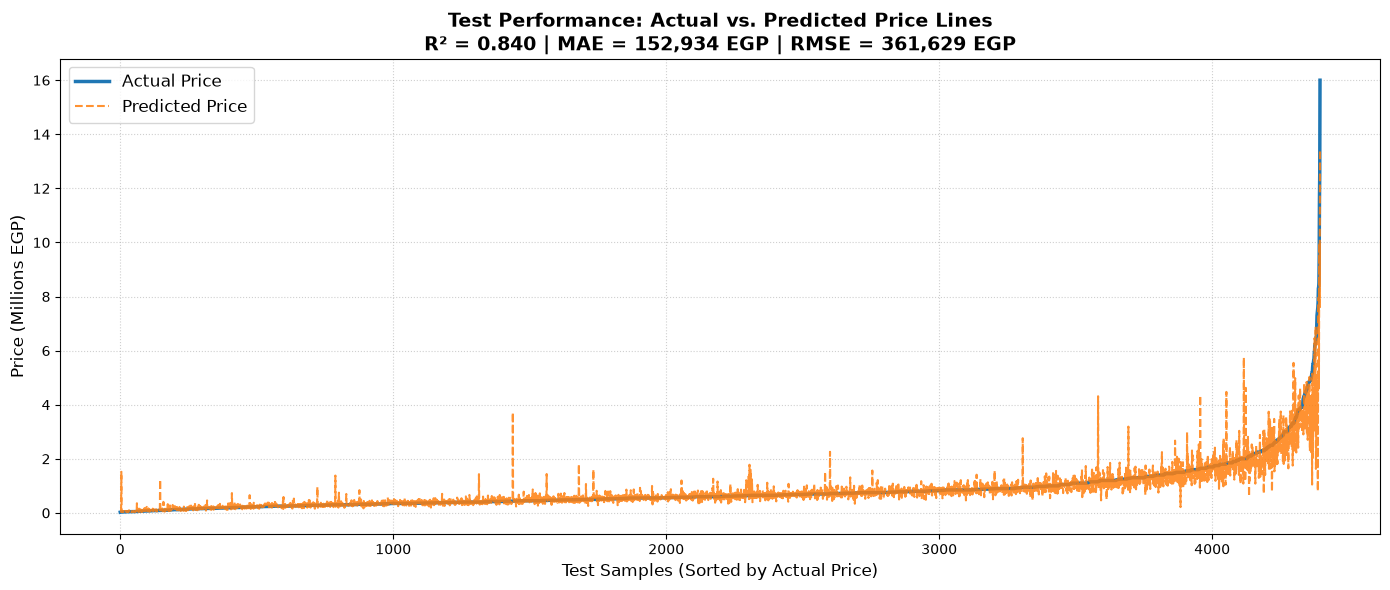

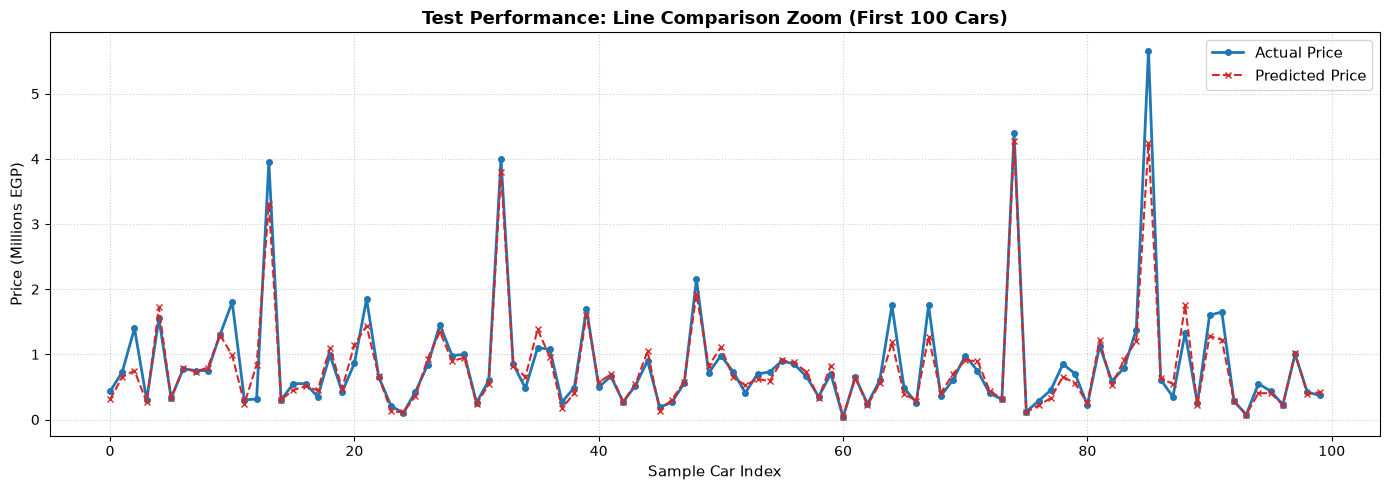

In [25]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Generate Predictions
y_train_pred = results['XGBoost']['model'].predict(X_train)
y_test_pred = results['XGBoost']['model'].predict(X_test)

test_mae = mean_absolute_error(y_test, y_test_pred)
test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred))
test_r2 = r2_score(y_test, y_test_pred)

# 2. Convert to numpy arrays & sort by actual price for smooth line comparison
y_test_arr = np.array(y_test)
sort_idx = np.argsort(y_test_arr)

y_test_sorted = y_test_arr[sort_idx] / 1e6
y_pred_sorted = y_test_pred[sort_idx] / 1e6


plt.figure(figsize=(14, 6))
plt.plot(y_test_sorted, label='Actual Price', color='#1f77b4', linewidth=2.5)
plt.plot(y_pred_sorted, label='Predicted Price', color='#ff7f0e', linestyle='--', linewidth=1.5, alpha=0.85)

plt.title(f'Test Performance: Actual vs. Predicted Price Lines\nR² = {test_r2:.3f} | MAE = {test_mae:,.0f} EGP | RMSE = {test_rmse:,.0f} EGP', 
          fontsize=14, fontweight='bold')
plt.xlabel('Test Samples (Sorted by Actual Price)', fontsize=12)
plt.ylabel('Price (Millions EGP)', fontsize=12)
plt.legend(loc='upper left', fontsize=12)
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()


sample_size = 100
plt.figure(figsize=(14, 5))
plt.plot(range(sample_size), y_test_arr[:sample_size] / 1e6, label='Actual Price', color='#1f77b4', marker='o', markersize=4, linewidth=2)
plt.plot(range(sample_size), y_test_pred[:sample_size] / 1e6, label='Predicted Price', color='#d62728', linestyle='--', marker='x', markersize=4, linewidth=1.5)

plt.title(f'Test Performance: Line Comparison Zoom (First {sample_size} Cars)', fontsize=13, fontweight='bold')
plt.xlabel('Sample Car Index', fontsize=11)
plt.ylabel('Price (Millions EGP)', fontsize=11)
plt.legend(loc='upper right', fontsize=11)
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()


=== OVERFITTING DIAGNOSTIC METRICS ===
Train R²: 0.9466  |  Test R²: 0.8400  (Gap: 0.1066)
Train MAE: 103,385 EGP |  Test MAE: 152,934 EGP (Error Ratio: 1.48x)


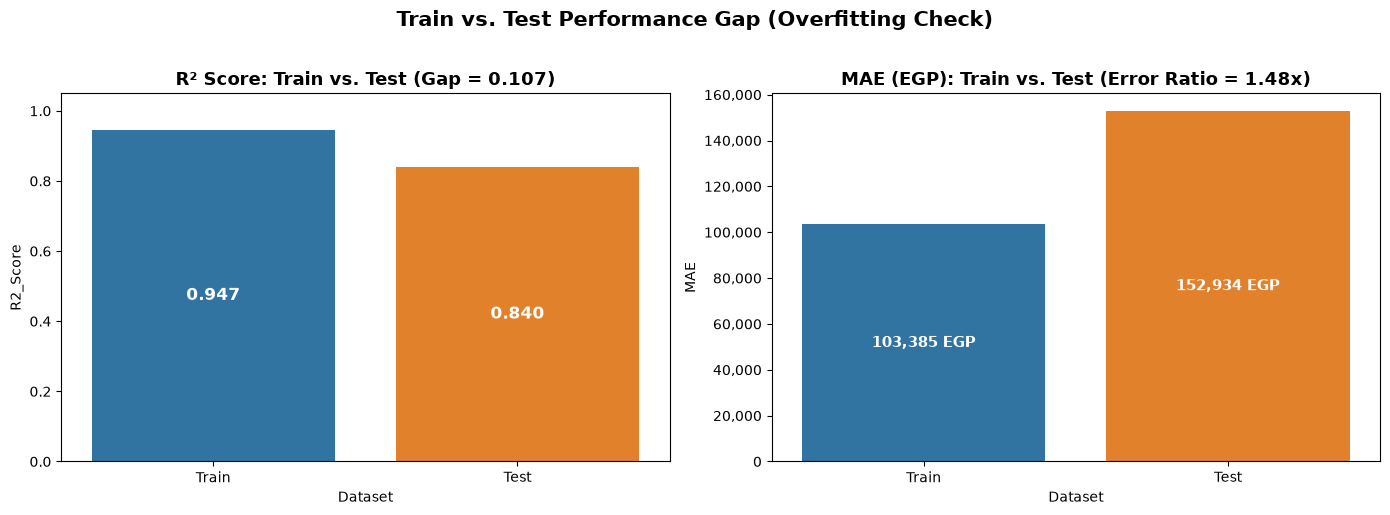

Generating Learning Curve... Please wait.


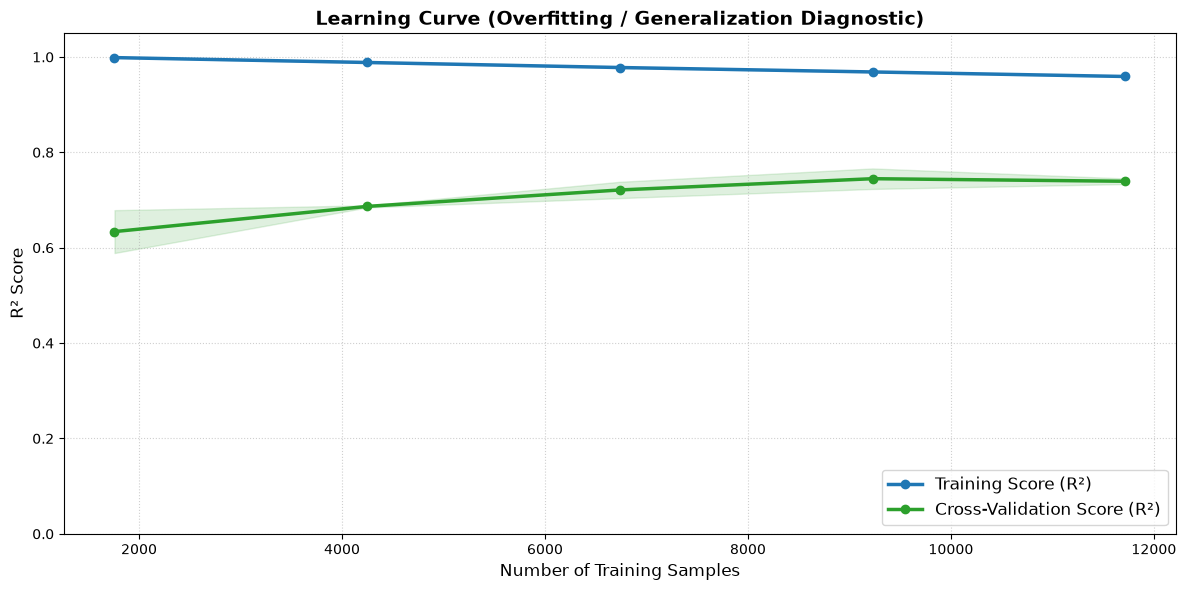

In [26]:

# ---------------------------------------------------------
# 1. CALCULATE TRAIN & TEST METRICS
# ---------------------------------------------------------
y_train_pred = results['XGBoost']['model'].predict(X_train)
y_test_pred =  results['XGBoost']['model'].predict(X_test)
metrics_data = {
    'Dataset': ['Train', 'Test'],
    'R2_Score': [r2_score(y_train, y_train_pred), r2_score(y_test, y_test_pred)],
    'MAE': [mean_absolute_error(y_train, y_train_pred), mean_absolute_error(y_test, y_test_pred)],
    'RMSE': [np.sqrt(mean_squared_error(y_train, y_train_pred)), np.sqrt(mean_squared_error(y_test, y_test_pred))]
}
metrics_df = pd.DataFrame(metrics_data)
# Print Gap Metrics
r2_gap = (metrics_df.loc[0, 'R2_Score'] - metrics_df.loc[1, 'R2_Score'])
mae_ratio = metrics_df.loc[1, 'MAE'] / metrics_df.loc[0, 'MAE']
print("=== OVERFITTING DIAGNOSTIC METRICS ===")
print(f"Train R²: {metrics_df.loc[0, 'R2_Score']:.4f}  |  Test R²: {metrics_df.loc[1, 'R2_Score']:.4f}  (Gap: {r2_gap:.4f})")
print(f"Train MAE: {metrics_df.loc[0, 'MAE']:,.0f} EGP |  Test MAE: {metrics_df.loc[1, 'MAE']:,.0f} EGP (Error Ratio: {mae_ratio:.2f}x)")
# ---------------------------------------------------------
# PLOT 1: TRAIN VS. TEST METRIC COMPARISON (BAR CHARTS)
# ---------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
# Subplot 1: R2 Score Comparison
sns.barplot(data=metrics_df, x='Dataset', y='R2_Score', palette=['#1f77b4', '#ff7f0e'], ax=axes[0])
axes[0].set_title(f'R² Score: Train vs. Test (Gap = {r2_gap:.3f})', fontsize=13, fontweight='bold')
axes[0].set_ylim(0, 1.05)
for p in axes[0].patches:
    axes[0].annotate(f'{p.get_height():.3f}', (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                     ha='center', va='center', fontsize=12, color='white', fontweight='bold')
# Subplot 2: MAE Comparison (in EGP)
sns.barplot(data=metrics_df, x='Dataset', y='MAE', palette=['#1f77b4', '#ff7f0e'], ax=axes[1])
axes[1].set_title(f'MAE (EGP): Train vs. Test (Error Ratio = {mae_ratio:.2f}x)', fontsize=13, fontweight='bold')
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda x, loc: f"{x:,.0f}"))
for p in axes[1].patches:
    axes[1].annotate(f'{p.get_height():,.0f} EGP', (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                     ha='center', va='center', fontsize=11, color='white', fontweight='bold')
plt.suptitle('Train vs. Test Performance Gap (Overfitting Check)', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()
# ---------------------------------------------------------
# PLOT 2: LEARNING CURVE (TRAIN VS. VALIDATION SCORE)
# ---------------------------------------------------------
print("Generating Learning Curve... Please wait.")
train_sizes, train_scores, cv_scores = learning_curve(
    estimator= results['XGBoost']['model'],
    X=X_train,
    y=y_train,
    cv=3,
    scoring='r2',
    train_sizes=np.linspace(0.15, 1.0, 5),
    n_jobs=-1,
    random_state=42
)
train_mean = np.mean(train_scores, axis=1)
train_std = np.std(train_scores, axis=1)
cv_mean = np.mean(cv_scores, axis=1)
cv_std = np.std(cv_scores, axis=1)
plt.figure(figsize=(12, 6))
plt.plot(train_sizes, train_mean, 'o-', color='#1f77b4', linewidth=2.5, label='Training Score (R²)')
plt.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, alpha=0.15, color='#1f77b4')
plt.plot(train_sizes, cv_mean, 'o-', color='#2ca02c', linewidth=2.5, label='Cross-Validation Score (R²)')
plt.fill_between(train_sizes, cv_mean - cv_std, cv_mean + cv_std, alpha=0.15, color='#2ca02c')
plt.title('Learning Curve (Overfitting / Generalization Diagnostic)', fontsize=14, fontweight='bold')
plt.xlabel('Number of Training Samples', fontsize=12)
plt.ylabel('R² Score', fontsize=12)
plt.ylim(0, 1.05)
plt.legend(loc='lower right', fontsize=12)
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

=== Brand Error & Sample Distribution Summary ===


,Make,Train_Count,Test_Count,Median_Price,MAE,MAPE
6,Mercedes,800,196,"1,985,000 EGP","549,749 EGP",31.03%
30,Audi,89,15,"1,650,000 EGP","457,447 EGP",20.11%
12,BMW,541,139,"1,500,000 EGP","369,985 EGP",18.48%
41,Volvo,35,10,"450,000 EGP","366,937 EGP",57.80%
21,Jeep,218,52,"935,000 EGP","262,387 EGP",19.57%
25,Honda,135,32,"505,000 EGP","202,293 EGP",64.01%
26,Seat,133,33,"900,000 EGP","176,130 EGP",33.44%
16,MG,406,106,"915,000 EGP","166,634 EGP",18.00%
10,Skoda,571,141,"625,000 EGP","162,967 EGP",18.94%
15,Volkswagen,428,90,"750,000 EGP","158,257 EGP",19.93%


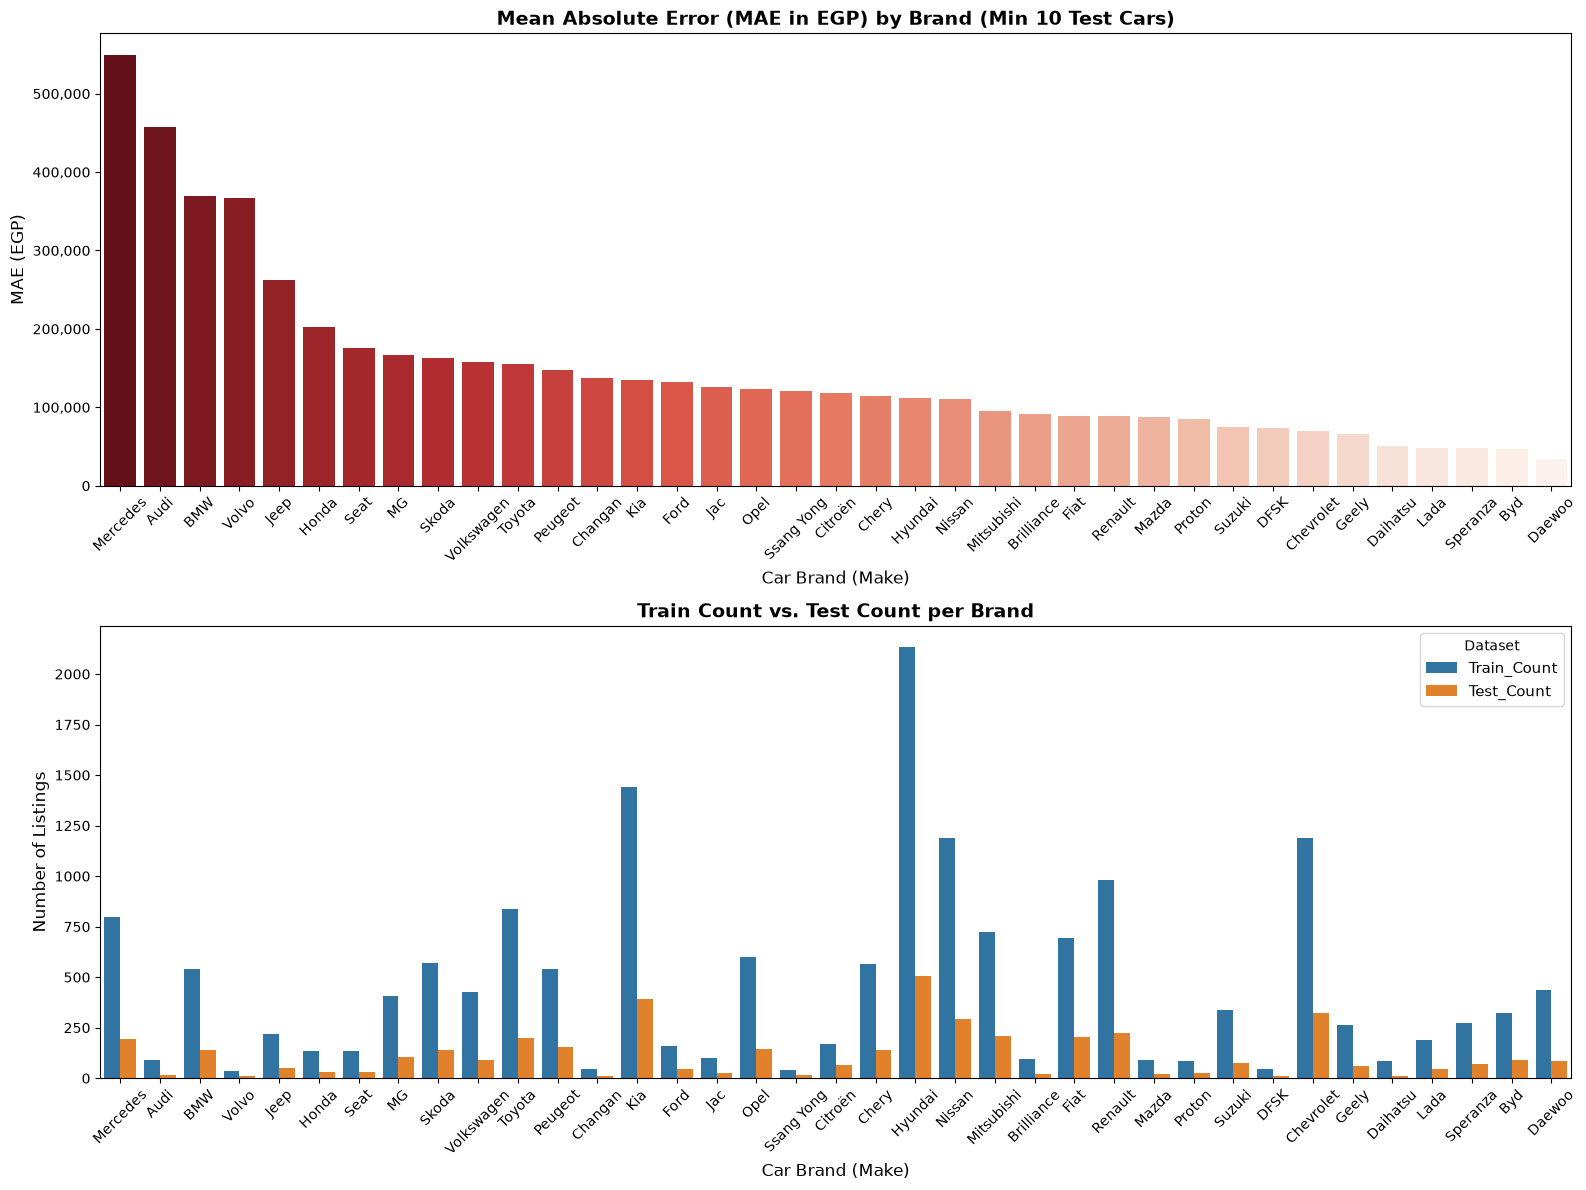

In [27]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ---------------------------------------------------------
# 1. COUNT LISTINGS IN TRAIN SET PER BRAND
# ---------------------------------------------------------
train_counts = X_train['Make'].value_counts().reset_index()
train_counts.columns = ['Make', 'Train_Count']

# ---------------------------------------------------------
# 2. COMPUTE TEST SET PREDICTION ERRORS PER BRAND
# ---------------------------------------------------------
test_results_df = X_test[['Make']].copy()
test_results_df['Actual_Price'] = y_test
test_results_df['Predicted_Price'] = y_test_pred

# Absolute Error and Percentage Error
test_results_df['Absolute_Error'] = np.abs(test_results_df['Actual_Price'] - test_results_df['Predicted_Price'])
test_results_df['Percentage_Error'] = (test_results_df['Absolute_Error'] / test_results_df['Actual_Price']) * 100

# Aggregate Test Metrics
brand_test_summary = test_results_df.groupby('Make').agg(
    Test_Count=('Actual_Price', 'count'),
    MAE=('Absolute_Error', 'mean'),
    MAPE=('Percentage_Error', 'mean'),
    Median_Price=('Actual_Price', 'median')
).reset_index()

# ---------------------------------------------------------
# 3. MERGE TRAIN & TEST DATA SUMMARIES
# ---------------------------------------------------------
brand_summary = pd.merge(train_counts, brand_test_summary, on='Make', how='left').fillna({
    'Test_Count': 0, 
    'MAE': 0, 
    'MAPE': 0
})

# Filter brands with at least 10 test listings for reliable statistics
min_test_cars = 10
brand_summary_filtered = brand_summary[brand_summary['Test_Count'] >= min_test_cars].sort_values(by='MAE', ascending=False)


# ---------------------------------------------------------
# 4. DISPLAY FORMATTED TABLE WITH TRAIN & TEST COUNTS
# ---------------------------------------------------------
print("=== Brand Error & Sample Distribution Summary ===")
display(brand_summary_filtered[['Make', 'Train_Count', 'Test_Count', 'Median_Price', 'MAE', 'MAPE']].head(15).style.format({
    'Train_Count': '{:,.0f}',
    'Test_Count': '{:,.0f}',
    'Median_Price': '{:,.0f} EGP',
    'MAE': '{:,.0f} EGP',
    'MAPE': '{:.2f}%'
}))


# ---------------------------------------------------------
# 5. PLOTS: MAE vs. TRAIN & TEST SAMPLE COUNTS
# ---------------------------------------------------------
fig, axes = plt.subplots(2, 1, figsize=(16, 12))

# --- Plot 1: MAE per Brand in EGP ---
sns.barplot(
    data=brand_summary_filtered,
    x='Make',
    y='MAE',
    palette='Reds_r',
    ax=axes[0]
)
axes[0].set_title(f'Mean Absolute Error (MAE in EGP) by Brand (Min {min_test_cars} Test Cars)', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Car Brand (Make)', fontsize=12)
axes[0].set_ylabel('MAE (EGP)', fontsize=12)
axes[0].tick_params(axis='x', rotation=45)
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda x, loc: f"{x:,.0f}"))

# --- Plot 2: Side-by-Side Bar Chart of Train Count vs. Test Count ---
brand_count_melted = pd.melt(
    brand_summary_filtered[['Make', 'Train_Count', 'Test_Count']],
    id_vars=['Make'],
    value_vars=['Train_Count', 'Test_Count'],
    var_name='Dataset',
    value_name='Listing_Count'
)

sns.barplot(
    data=brand_count_melted,
    x='Make',
    y='Listing_Count',
    hue='Dataset',
    palette=['#1f77b4', '#ff7f0e'],
    ax=axes[1]
)
axes[1].set_title('Train Count vs. Test Count per Brand', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Car Brand (Make)', fontsize=12)
axes[1].set_ylabel('Number of Listings', fontsize=12)
axes[1].tick_params(axis='x', rotation=45)
axes[1].legend(title='Dataset', fontsize=11)

plt.tight_layout()
plt.show()


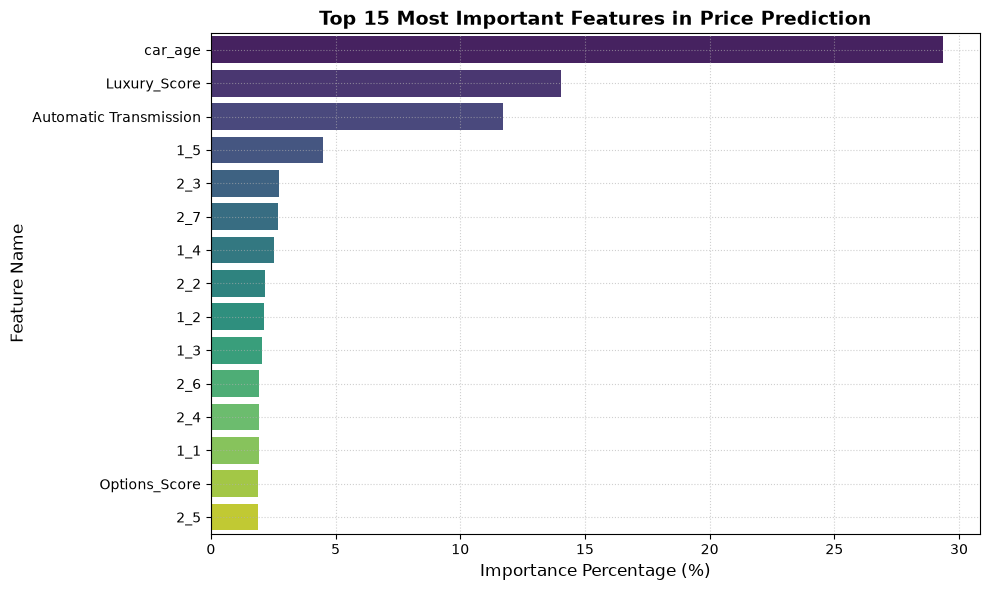

In [28]:
raw_features =  results['XGBoost']['model'].named_steps['preprocess'].get_feature_names_out()
clean_features = [col.split('__')[-1] for col in raw_features]
underlying_model =  results['XGBoost']['model'].named_steps['regressor'].regressor_
importances = underlying_model.feature_importances_
fi_df = pd.DataFrame({
    'Feature': clean_features,
    'Raw_Importance': importances
})
fi_df['Importance_Percentage (%)'] = (fi_df['Raw_Importance'] / fi_df['Raw_Importance'].sum()) * 100
fi_df = fi_df.sort_values(by='Raw_Importance', ascending=False).reset_index(drop=True)

plt.figure(figsize=(10, 6))
sns.barplot(
    data=fi_df.head(15),
    x='Importance_Percentage (%)',
    y='Feature',
    palette='viridis'
)
plt.title('Top 15 Most Important Features in Price Prediction', fontsize=14, fontweight='bold')
plt.xlabel('Importance Percentage (%)', fontsize=12)
plt.ylabel('Feature Name', fontsize=12)
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

In [29]:
joblib.dump(best_model, "xgb_pipeline.joblib")
joblib.dump(
    {
        "brand_medians": brand_medians.to_dict(),
        "global_median": float(global_median),
    },"brand_stats.joblib",)

['brand_stats.joblib']